In [131]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from dask.diagnostics import ProgressBar

import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [132]:
run = 'oper_04'

In [133]:
path_data = f'/jetfs/scratch/psplechtna/flexpart_output/oper/2024/{run}/processed_data/'
filename_sw_rad = f'{path_data}rad_sw.zarr'
filename_lw_rad = f'{path_data}rad_lw.zarr'
filename_lh_flux = f'{path_data}lh_bl.zarr'
filename_sh_flux = f'{path_data}sh_bl.zarr'

In [134]:
def deg_to_rad(angle):
    return angle*np.pi/180

def grid_cell_area(lon_width, lat_width, radius, lower_lat):
    a = radius**2 * deg_to_rad(lon_width) * (np.sin(deg_to_rad(lower_lat+lat_width)) - np.sin(deg_to_rad(lower_lat)))
    return a

In [135]:
r = 6371e3 # radius of the Earth in m
res = 0.5 # resolution of the grid in degrees
cp = 1005.  


## for single release

In [136]:
release = 3

In [137]:
with ProgressBar():
    sw_rad =xr.open_mfdataset(filename_sw_rad, engine='zarr').sel(pointspec=release).sum(dim='time').rad_sw.load()*cp
    lw_rad =xr.open_mfdataset(filename_lw_rad, engine='zarr').sel(pointspec=release).sum(dim='time').rad_lw.load()*cp
    lh_flux =xr.open_mfdataset(filename_lh_flux, engine='zarr').sel(pointspec=release).sum(dim='time').lh_bl.load()
    sh_flux =xr.open_mfdataset(filename_sh_flux, engine='zarr').sel(pointspec=release).sum(dim='time').sh_bl.load()


[########################################] | 100% Completed | 3.30 sms
[########################################] | 100% Completed | 3.31 sms
[########################################] | 100% Completed | 2.05 sms
[########################################] | 100% Completed | 2.05 sms


with ProgressBar():
    sw_rad =xr.open_mfdataset(filename_sw_rad, engine='zarr').sel(pointspec=release).isel(time=200).rad_sw.load()*cp
    lw_rad =xr.open_mfdataset(filename_lw_rad, engine='zarr').sel(pointspec=release).isel(time=200).rad_lw.load()*cp
    lh_flux =xr.open_mfdataset(filename_lh_flux, engine='zarr').sel(pointspec=release).isel(time=200).lh_bl.load()
    sh_flux =xr.open_mfdataset(filename_sh_flux, engine='zarr').sel(pointspec=release).isel(time=200).sh_bl.load()


In [138]:
sw_rad = sw_rad/grid_cell_area(res, res, r, sw_rad.latitude)
lw_rad = lw_rad/grid_cell_area(res, res, r, lw_rad.latitude)
lh_flux = lh_flux/grid_cell_area(res, res, r, lh_flux.latitude)
sh_flux = sh_flux/grid_cell_area(res, res, r, sh_flux.latitude)

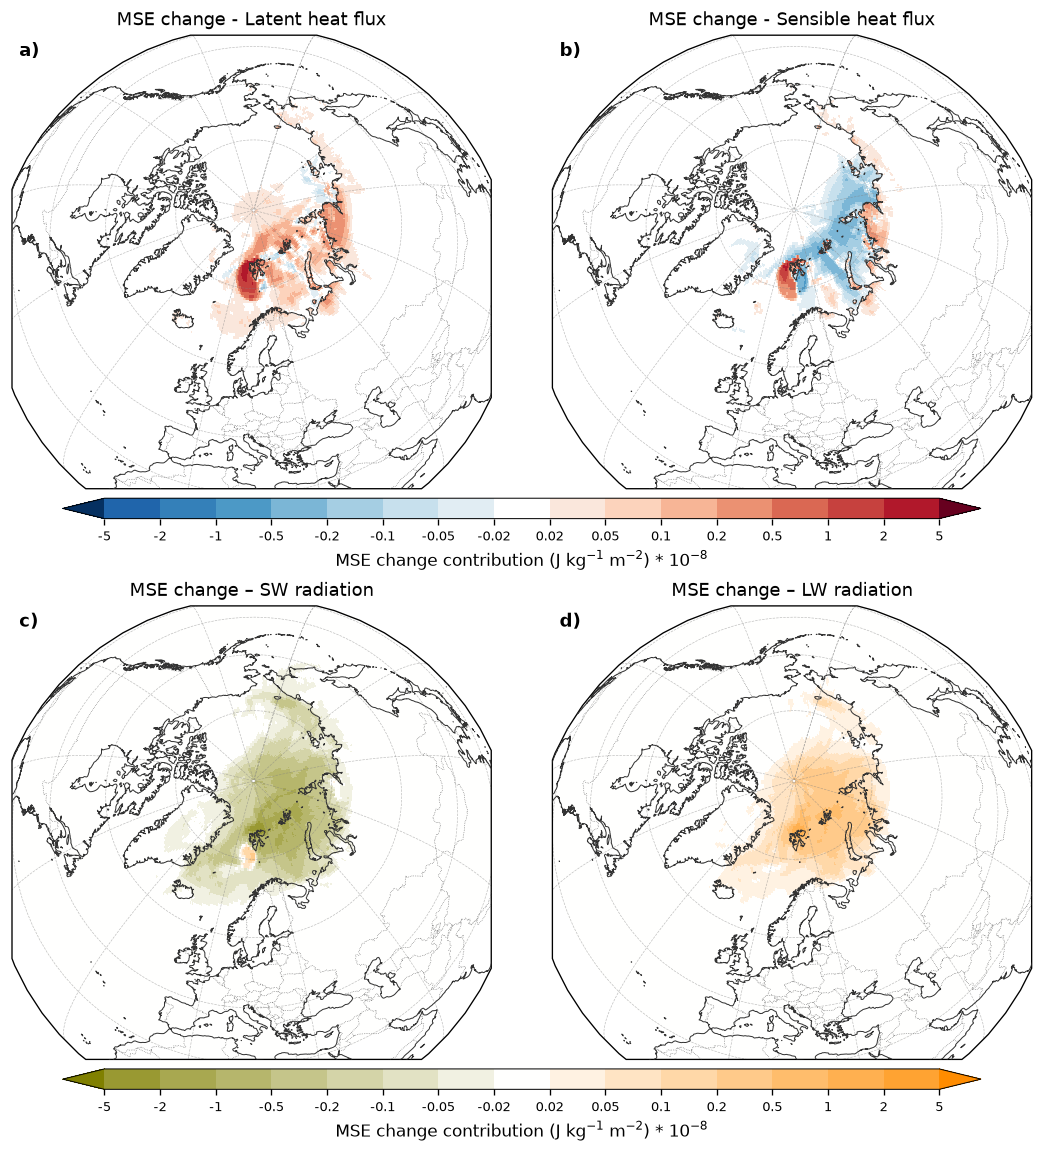

In [139]:
# ---------------------------------------------------------------------
# 0. general style / map settings
# ---------------------------------------------------------------------
plt.rcParams.update({
    "font.family":     "sans",
    "font.size":       10,
    "axes.titlesize":  11,
    "axes.labelsize":  10,
    "figure.dpi":      120,
    "savefig.dpi":     300,
})

lonmin, lonmax = -179, 180
latmin, latmax =   30,  90

map_proj  = ccrs.NearsidePerspective(central_longitude=15, central_latitude=75)
data_proj = ccrs.PlateCarree()

CBAR_LABEL = r'MSE change contribution (J kg$^{-1}$ m$^{-2}$)'


# ---------------------------------------------------------------------
# 1. helpers: colormaps and array handling
# ---------------------------------------------------------------------
def discrete_cmap_norm(boundaries, cmap, white_center=False,
                       under=None, over=None, name='custom'):
    """Discrete ListedColormap + BoundaryNorm with separate under/over colours."""
    boundaries = np.asarray(boundaries, dtype=float)
    n = len(boundaries) - 1

    base = (plt.get_cmap(cmap) if isinstance(cmap, str)
        else cmap.resampled(256))

    # Use the central 80% of the colormap for the actual bins
    cols = [base(x) for x in np.linspace(0.1, 0.9, n)]

    if white_center and n % 2 == 1:
        cols[n // 2] = (1, 1, 1, 1)

    cm = mcolors.ListedColormap(cols, name=name)

    # Separate colours for the triangular extensions
    cm.set_under(under if under is not None else base(0.0))
    cm.set_over(over if over is not None else base(1.0))
    cm.set_bad('lightgrey')

    return cm, mcolors.BoundaryNorm(
    boundaries, ncolors=n, extend='neither'
)


def as_arrays(field, lon=None, lat=None, lon_name='lon', lat_name='lat'):
    """
    Return (lon2d, lat2d, data2d) as plain numpy arrays.

    `field` may be
      * a 2-D numpy array (then `lon`/`lat` must be given, 1-D or 2-D), or
      * an xarray.DataArray, in which case lon/lat are taken from its
        coordinates when not supplied explicitly.
    """
    # --- pull coordinates out of an xarray-like object, if present --------
    if hasattr(field, 'dims') and hasattr(field, 'coords'):
        if lon is None and lon_name in field.coords:
            lon = np.asarray(field.coords[lon_name].values)
        if lat is None and lat_name in field.coords:
            lat = np.asarray(field.coords[lat_name].values)
        dims = list(field.dims)
        data = np.asarray(field.values)
    else:
        data = np.asarray(field)
        dims = None

    data = np.squeeze(data)
    if data.ndim != 2:
        raise ValueError(f"expected a 2-D field, got shape {data.shape}")
    if lon is None or lat is None:
        raise ValueError("lon/lat must be provided for plain numpy input")

    lon = np.asarray(lon, dtype=float)
    lat = np.asarray(lat, dtype=float)

    # --- make sure data is ordered (lat, lon) -----------------------------
    if lon.ndim == 1 and lat.ndim == 1:
        if dims is not None and dims[0] == lon_name:
            data = data.T
        elif data.shape == (lon.size, lat.size) and lon.size != lat.size:
            data = data.T
        if data.shape != (lat.size, lon.size):
            raise ValueError(f"shape mismatch: data {data.shape} vs "
                             f"(lat, lon) = {(lat.size, lon.size)}")
        lon2d, lat2d = np.meshgrid(lon, lat)
    else:                                   # curvilinear / already 2-D
        lon2d, lat2d = np.broadcast_arrays(lon, lat)
        if data.shape != lon2d.shape:
            data = data.T
        if data.shape != lon2d.shape:
            raise ValueError("2-D coordinates do not match the data shape")

    return lon2d, lat2d, np.ma.masked_invalid(data)


def map_pcolormesh(ax, field, lon=None, lat=None, **kwargs):
    """numpy- or xarray-input -> ax.pcolormesh on a cartopy axis."""
    lon2d, lat2d, data = as_arrays(field, lon, lat)
    kwargs.setdefault('transform', data_proj)
    kwargs.setdefault('shading', 'auto')
    kwargs.setdefault('rasterized', True)
    return ax.pcolormesh(lon2d, lat2d, data, **kwargs)


# ---------------------------------------------------------------------
# 2. the three colormaps
# ---------------------------------------------------------------------
# diverging, white centre -- panels 0 and 1
bounds_div = np.array([-5, -2, -1, -0.5, -0.2, -0.1, -0.05, -0.02,
                       0.02, 0.05, 0.1, 0.2, 0.5, 1, 2, 5]) * 1e-8
cmap_div, norm_div = discrete_cmap_norm(
    bounds_div, 'RdBu_r', white_center=True,
    under=plt.get_cmap('RdBu_r')(0.0), over=plt.get_cmap('RdBu_r')(1.0),
    name='RdBu_r_white')

# Shared white-centred colormap for panels c and d
shared_cmap = mcolors.LinearSegmentedColormap.from_list(
    'white_olive_orange',
    ['olive', 'white', 'darkorange'],
    N=len(bounds_div) - 1
)

cmap_shared, norm_shared = discrete_cmap_norm(
    bounds_div,
    shared_cmap,
    name='shared_olive_orange'
)

# ---------------------------------------------------------------------
# 4. figure layout
# ---------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(9, 9.5),
                         subplot_kw={'projection': map_proj},
                         constrained_layout=True)
axs = axes.flatten()


def decorate(ax, title=None, label=None):
    ax.set_extent([lonmin, lonmax, latmin, latmax], crs=data_proj)
    #ax.add_feature(cfeature.LAND.with_scale('50m'),  facecolor='0.92', zorder=0)
    ax.add_feature(cfeature.OCEAN.with_scale('50m'), facecolor='white', zorder=0)
    ax.add_feature(cfeature.COASTLINE.with_scale('50m'),
                   linewidth=0.6, edgecolor='0.2', zorder=5)
    ax.add_feature(cfeature.BORDERS.with_scale('50m'),
                   linewidth=0.4, linestyle=':', edgecolor='0.4', zorder=5)
    ax.gridlines(crs=data_proj, draw_labels=False, linewidth=0.4,
                 color='grey', alpha=0.5, linestyle='--',
                 xlocs=np.arange(-180, 181, 30),
                 ylocs=np.arange(30, 91, 15), zorder=6)
    ax.spines['geo'].set_linewidth(0.8)
    if title:
        ax.set_title(title, pad=6)
    if label:
        ax.text(0.015, 0.985, label, transform=ax.transAxes,
                ha='left', va='top', fontweight='bold', fontsize=11)#,
                #bbox=dict(boxstyle='round,pad=0.25', fc='white',
                          #ec='0.5', lw=0.6, alpha=0.85), zorder=10)


panel_titles = ['MSE change - Latent heat flux', 
                'MSE change - Sensible heat flux',
                'MSE change – SW radiation',
                'MSE change – LW radiation']
for ax, ttl, lab in zip(axs, panel_titles, ['a)', 'b)', 'c)', 'd)']):
    decorate(ax, ttl, lab)


def add_cbar(mappable, ax, boundaries, label, scale=1e8, extend='both'):
    cb = fig.colorbar(mappable, ax=ax, orientation='horizontal',
                      extend=extend, fraction=0.045, pad=0.02, aspect=45,
                      ticks=boundaries)
    cb.set_label(label+r' * 10$^{-8}$')
    cb.ax.set_xticklabels([f'{b * scale:g}' for b in boundaries])
    cb.ax.tick_params(labelsize=8)
    cb.outline.set_linewidth(0.6)
    return cb


# ---------------------------------------------------------------------
# 5. panels 0 and 1 -- empty for now
# ---------------------------------------------------------------------
# when your data are ready, replace the dummy mappable below with, e.g.:
m0 = map_pcolormesh(axs[0], lh_flux, lh_flux.longitude, lh_flux.latitude, cmap=cmap_div, norm=norm_div)
m1 = map_pcolormesh(axs[1], sh_flux, sh_flux.longitude, sh_flux.latitude, cmap=cmap_div, norm=norm_div)
add_cbar(m0, axs[:2].tolist(), bounds_div, CBAR_LABEL)
#sm_div = plt.cm.ScalarMappable(cmap=cmap_div, norm=norm_div)
#add_cbar(sm_div, axs[:2].tolist(), bounds_div, CBAR_LABEL, extend='both')


# ---------------------------------------------------------------------
# 6. panels 2 and 3 -- SW and LW
# ---------------------------------------------------------------------
m2 = map_pcolormesh(
    axs[2], lw_rad, lw_rad.longitude, lw_rad.latitude,
    cmap=cmap_shared, norm=norm_shared
)

m3 = map_pcolormesh(
    axs[3], sw_rad, sw_rad.longitude, sw_rad.latitude,
    cmap=cmap_shared, norm=norm_shared
)

add_cbar(
    m2, axs[2:4].tolist(),
    bounds_div, CBAR_LABEL,
    extend='both'
)

#fig.savefig('spatial_blh.png')